In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine, text
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (roc_auc_score, classification_report,
                             confusion_matrix, RocCurveDisplay,
                             PrecisionRecallDisplay)
from sklearn.linear_model import LogisticRegression
import xgboost as xgb
import shap
import warnings
warnings.filterwarnings("ignore")

plt.rcParams.update({
    "figure.dpi":        150,
    "figure.figsize":    (12, 5),
    "axes.spines.top":   False,
    "axes.spines.right": False,
    "axes.titlesize":    14,
    "axes.titleweight":  "bold",
    "font.family":       "sans-serif",
})

DB_PATH = r"D:\customer_intelligence_platform\data\processed\olist.db"
engine  = create_engine(f"sqlite:///{DB_PATH}")

def sql(query):
    with engine.connect() as conn:
        return pd.read_sql(text(query), conn)

print("Ready for churn modeling")

Ready for churn modeling


Churn dataset built: (93396, 17)

Churn rate: 70.6%
Churned customers : 65,907
Active customers  : 27,489


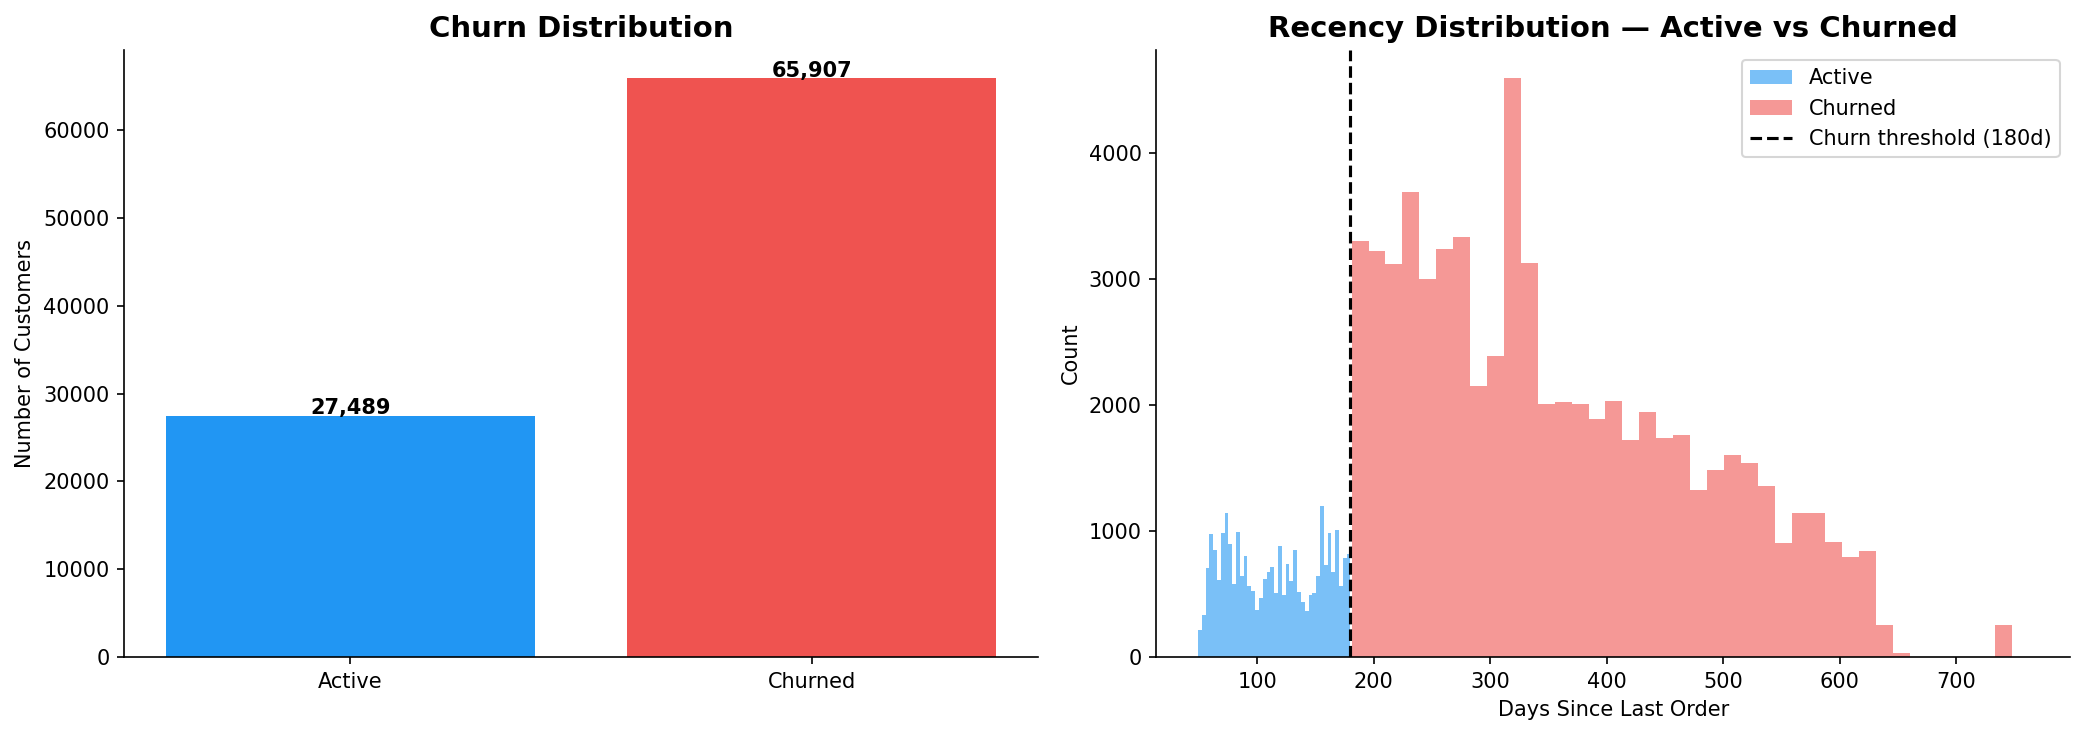

In [2]:
# ── Define churn: no order in last 180 days of dataset ───────────────────────
churn_data = sql("""
    WITH customer_stats AS (
        SELECT
            mo.customer_unique_id,

            -- Recency
            CAST(JULIANDAY(
                (SELECT MAX(order_purchase_timestamp) FROM master_orders)
            ) - JULIANDAY(MAX(mo.order_purchase_timestamp)) AS INTEGER)
                                                        AS recency_days,

            -- Order behavior
            COUNT(DISTINCT mo.order_id)                 AS total_orders,
            ROUND(SUM(mo.total_payment), 2)             AS total_spend,
            ROUND(AVG(mo.total_payment), 2)             AS avg_order_value,
            ROUND(AVG(mo.review_score), 2)              AS avg_review_score,
            ROUND(AVG(mo.delivery_days), 1)             AS avg_delivery_days,
            ROUND(AVG(mo.delivery_delay_days), 1)       AS avg_delay_days,
            COUNT(DISTINCT mo.purchase_month)           AS active_months,

            -- Payment behavior
            MAX(CASE WHEN mo.payment_type = 'credit_card'
                     THEN 1 ELSE 0 END)                 AS uses_credit_card,
            MAX(CASE WHEN mo.payment_type = 'boleto'
                     THEN 1 ELSE 0 END)                 AS uses_boleto,
            ROUND(AVG(mo.payment_installments), 1)      AS avg_installments,

            -- Delivery experience
            SUM(CASE WHEN mo.delivery_delay_days > 0
                     THEN 1 ELSE 0 END)                 AS num_late_orders,
            SUM(CASE WHEN mo.review_score <= 2
                     THEN 1 ELSE 0 END)                 AS num_bad_reviews,
            SUM(CASE WHEN mo.review_score = 5
                     THEN 1 ELSE 0 END)                 AS num_perfect_reviews,

            -- Geography
            mo.customer_state

        FROM master_orders mo
        WHERE mo.order_status = 'delivered'
        GROUP BY mo.customer_unique_id, mo.customer_state
    )
    SELECT *,
        CASE WHEN recency_days > 180 THEN 1 ELSE 0 END AS churned
    FROM customer_stats
""")

print(f"Churn dataset built: {churn_data.shape}")
print(f"\nChurn rate: {churn_data['churned'].mean()*100:.1f}%")
print(f"Churned customers : {churn_data['churned'].sum():,}")
print(f"Active customers  : {(churn_data['churned']==0).sum():,}")

# Quick churn distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(["Active", "Churned"],
            churn_data["churned"].value_counts().sort_index().values,
            color=["#2196F3", "#EF5350"])
axes[0].set_title("Churn Distribution")
axes[0].set_ylabel("Number of Customers")
for i, v in enumerate(churn_data["churned"].value_counts().sort_index().values):
    axes[0].text(i, v + 200, f"{v:,}", ha="center", fontweight="bold")

axes[1].hist(churn_data[churn_data["churned"]==0]["recency_days"],
             bins=40, alpha=0.6, color="#2196F3", label="Active")
axes[1].hist(churn_data[churn_data["churned"]==1]["recency_days"],
             bins=40, alpha=0.6, color="#EF5350", label="Churned")
axes[1].axvline(180, color="black", linestyle="--", label="Churn threshold (180d)")
axes[1].set_title("Recency Distribution — Active vs Churned")
axes[1].set_xlabel("Days Since Last Order")
axes[1].set_ylabel("Count")
axes[1].legend()

plt.tight_layout()
plt.savefig(r"D:\customer_intelligence_platform\outputs\10_churn_distribution.png",
            bbox_inches="tight")
plt.show()

In [3]:
# ── Prepare features ──────────────────────────────────────────────────────────
df = churn_data.copy()

# Fill nulls
df["avg_review_score"]  = df["avg_review_score"].fillna(3.0)
df["avg_delay_days"]    = df["avg_delay_days"].fillna(0)
df["avg_delivery_days"] = df["avg_delivery_days"].fillna(df["avg_delivery_days"].median())
df["avg_installments"]  = df["avg_installments"].fillna(1)

# Derived features
df["late_order_rate"]    = df["num_late_orders"]   / df["total_orders"]
df["bad_review_rate"]    = df["num_bad_reviews"]   / df["total_orders"]
df["perfect_review_rate"]= df["num_perfect_reviews"]/ df["total_orders"]
df["spend_per_month"]    = df["total_spend"]        / df["active_months"].clip(lower=1)

# Encode top states (top 5 get dummies, rest = "other")
top_states = df["customer_state"].value_counts().head(5).index.tolist()
df["customer_state"] = df["customer_state"].apply(
    lambda x: x if x in top_states else "other")
state_dummies = pd.get_dummies(df["customer_state"], prefix="state")
df = pd.concat([df, state_dummies], axis=1)

# Final feature list
FEATURES = [
    "total_orders", "total_spend", "avg_order_value",
    "avg_review_score", "avg_delivery_days", "avg_delay_days",
    "active_months", "uses_credit_card", "uses_boleto",
    "avg_installments", "num_late_orders", "num_bad_reviews",
    "num_perfect_reviews", "late_order_rate", "bad_review_rate",
    "perfect_review_rate", "spend_per_month",
] + [c for c in state_dummies.columns]

TARGET = "churned"

X = df[FEATURES]
y = df[TARGET]

print(f"Features ready: {X.shape}")
print(f"   Feature count : {len(FEATURES)}")
print(f"\nFeature list:")
for f in FEATURES:
    print(f"  • {f}")

Features ready: (93396, 23)
   Feature count : 23

Feature list:
  • total_orders
  • total_spend
  • avg_order_value
  • avg_review_score
  • avg_delivery_days
  • avg_delay_days
  • active_months
  • uses_credit_card
  • uses_boleto
  • avg_installments
  • num_late_orders
  • num_bad_reviews
  • num_perfect_reviews
  • late_order_rate
  • bad_review_rate
  • perfect_review_rate
  • spend_per_month
  • state_MG
  • state_PR
  • state_RJ
  • state_RS
  • state_SP
  • state_other


In [4]:
# ── Train/test split ──────────────────────────────────────────────────────────
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Train: {X_train.shape}  |  Test: {X_test.shape}")
print(f"Train churn rate: {y_train.mean()*100:.1f}%")
print(f"Test  churn rate: {y_test.mean()*100:.1f}%")

# ── XGBoost ───────────────────────────────────────────────────────────────────
scale_pos = (y_train == 0).sum() / (y_train == 1).sum()

xgb_model = xgb.XGBClassifier(
    n_estimators      = 300,
    max_depth         = 5,
    learning_rate     = 0.05,
    subsample         = 0.8,
    colsample_bytree  = 0.8,
    scale_pos_weight  = scale_pos,
    random_state      = 42,
    eval_metric       = "auc",
    early_stopping_rounds = 20,
    verbosity         = 0,
)

xgb_model.fit(
    X_train, y_train,
    eval_set=[(X_test, y_test)],
    verbose=False
)

# ── Evaluate ──────────────────────────────────────────────────────────────────
y_pred_proba = xgb_model.predict_proba(X_test)[:, 1]
y_pred       = xgb_model.predict(X_test)

auc = roc_auc_score(y_test, y_pred_proba)

print(f"\n{'='*45}")
print(f"  XGBoost ROC-AUC Score : {auc:.4f}")
print(f"{'='*45}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred,
                            target_names=["Active", "Churned"]))

# ── Cross validation ──────────────────────────────────────────────────────────
cv_model = xgb.XGBClassifier(
    n_estimators=300, max_depth=5, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8,
    scale_pos_weight=scale_pos, random_state=42,
    verbosity=0
)
cv_scores = cross_val_score(cv_model, X, y, cv=5,
                            scoring="roc_auc", n_jobs=-1)
print(f"\n5-Fold CV AUC: {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")

Train: (74716, 23)  |  Test: (18680, 23)
Train churn rate: 70.6%
Test  churn rate: 70.6%

  XGBoost ROC-AUC Score : 0.7476

Classification Report:
              precision    recall  f1-score   support

      Active       0.48      0.66      0.56      5498
     Churned       0.83      0.70      0.76     13182

    accuracy                           0.69     18680
   macro avg       0.66      0.68      0.66     18680
weighted avg       0.73      0.69      0.70     18680


5-Fold CV AUC: 0.7512 ± 0.0042


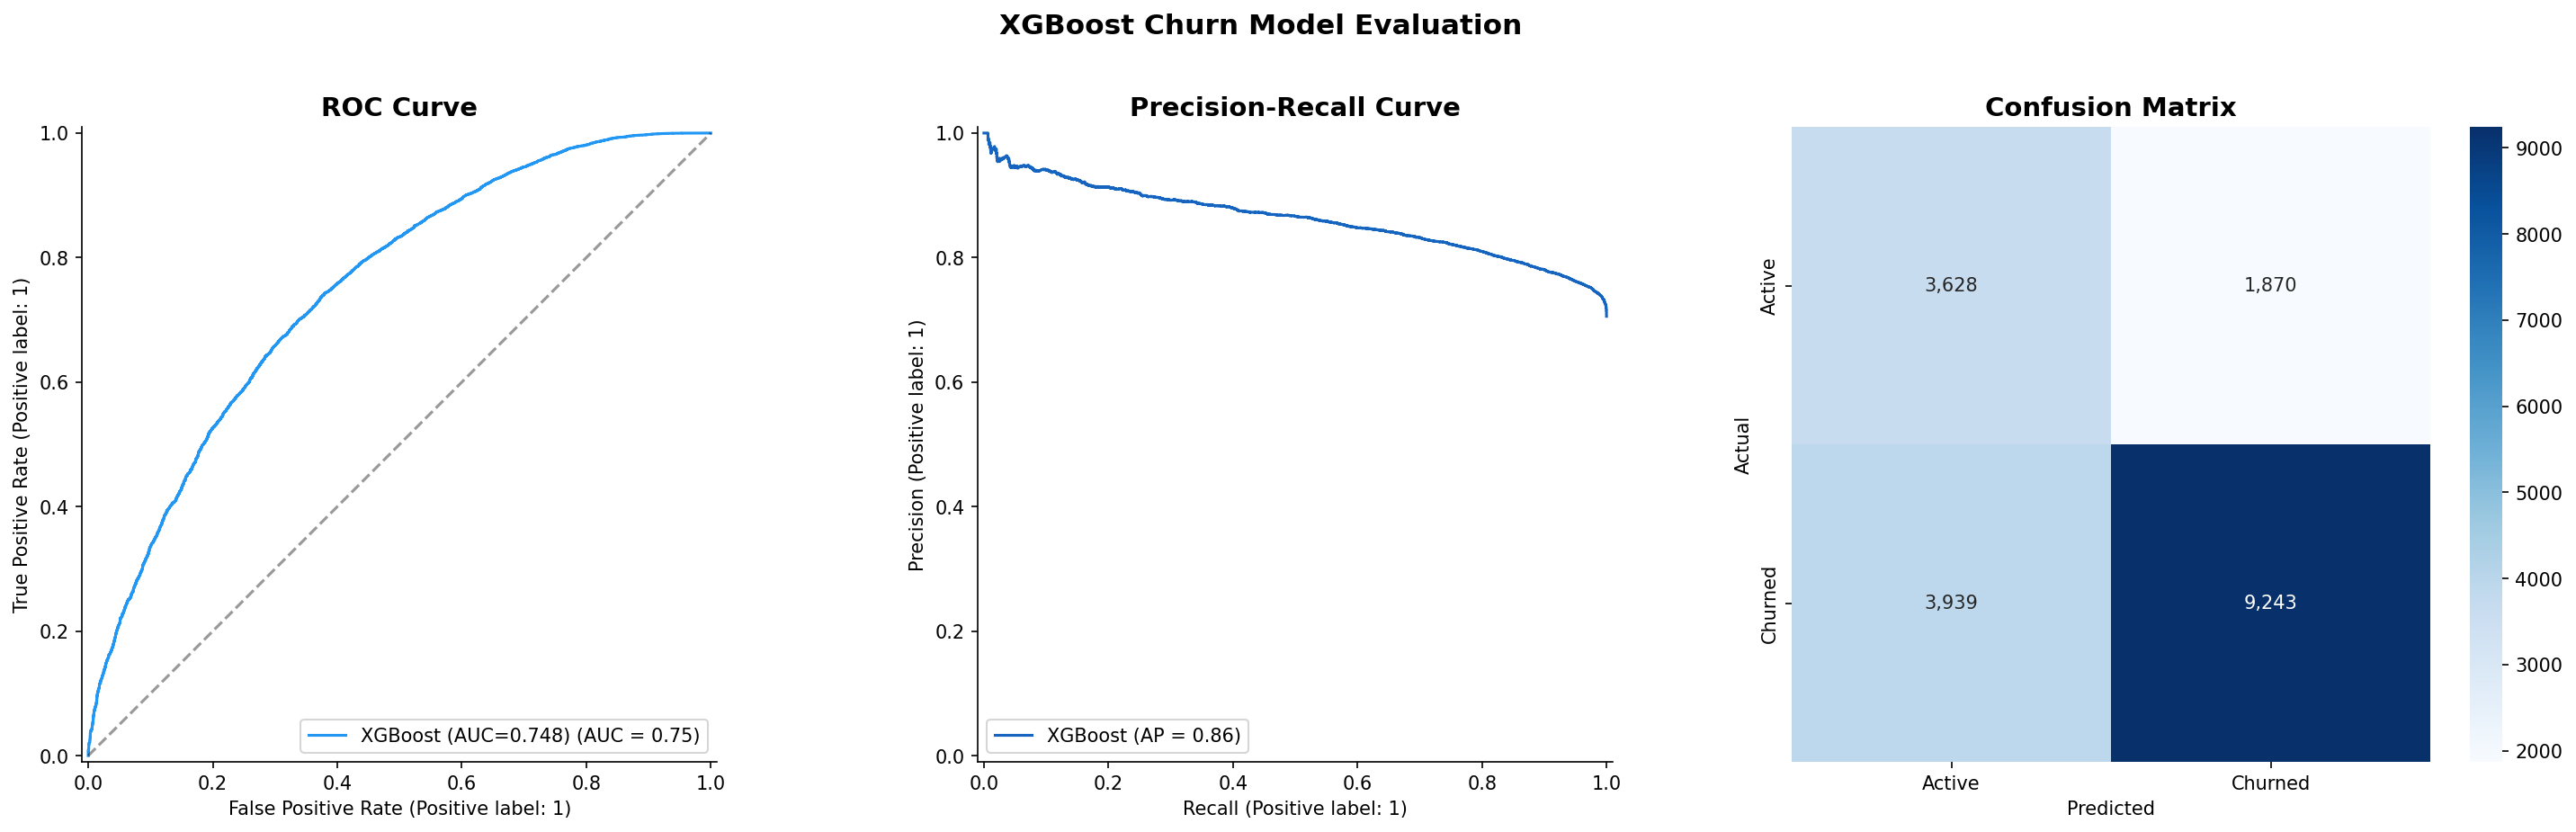

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# 1. ROC Curve
RocCurveDisplay.from_predictions(
    y_test, y_pred_proba, ax=axes[0],
    color="#2196F3", name=f"XGBoost (AUC={auc:.3f})")
axes[0].plot([0,1],[0,1], "k--", alpha=0.4)
axes[0].set_title("ROC Curve")

# 2. Precision-Recall
PrecisionRecallDisplay.from_predictions(
    y_test, y_pred_proba, ax=axes[1],
    color="#1565C0", name="XGBoost")
axes[1].set_title("Precision-Recall Curve")

# 3. Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt=",", cmap="Blues",
            xticklabels=["Active","Churned"],
            yticklabels=["Active","Churned"],
            ax=axes[2])
axes[2].set_title("Confusion Matrix")
axes[2].set_ylabel("Actual")
axes[2].set_xlabel("Predicted")

plt.suptitle("XGBoost Churn Model Evaluation",
             fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(r"D:\customer_intelligence_platform\outputs\11_model_evaluation.png",
            bbox_inches="tight")
plt.show()

Computing SHAP values (30-60 seconds)...


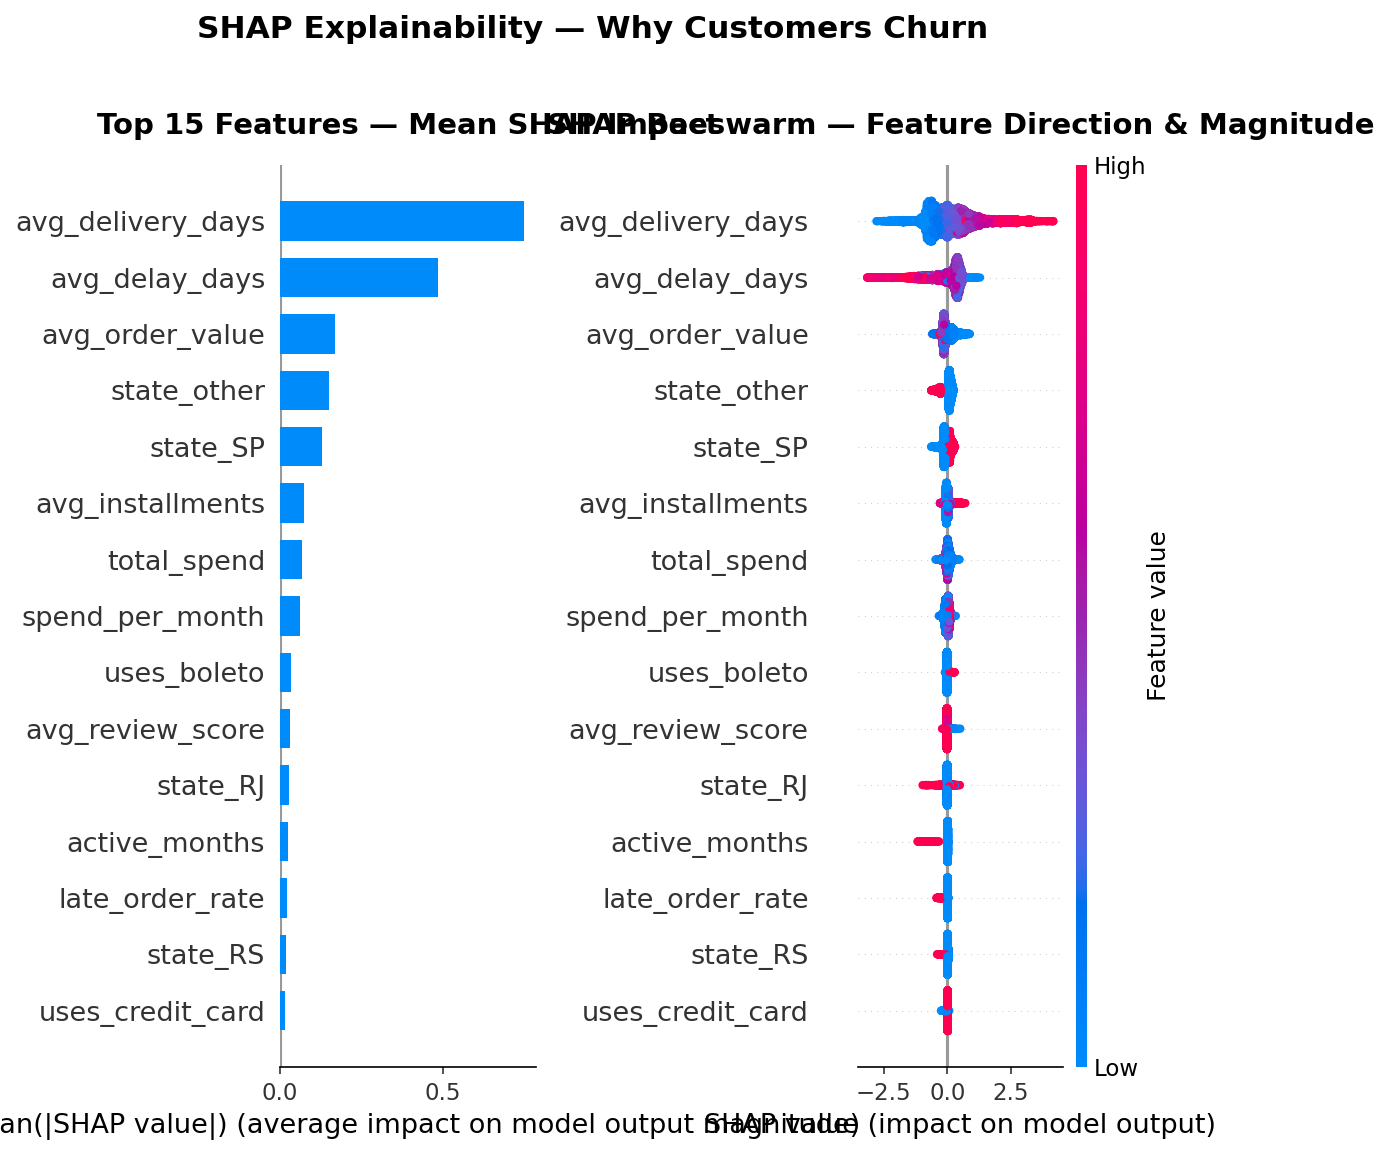


Top 10 Churn Drivers:
          feature  mean_shap
avg_delivery_days   0.747864
   avg_delay_days   0.485713
  avg_order_value   0.167705
      state_other   0.149622
         state_SP   0.127753
 avg_installments   0.073253
      total_spend   0.067524
  spend_per_month   0.063038
      uses_boleto   0.034065
 avg_review_score   0.032567


In [6]:
# ── SHAP values ───────────────────────────────────────────────────────────────
print("Computing SHAP values (30-60 seconds)...")

explainer   = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_test)

fig, axes = plt.subplots(1, 2, figsize=(20, 8))

# 1. SHAP summary bar plot
plt.sca(axes[0])
shap.summary_plot(shap_values, X_test,
                  plot_type="bar",
                  max_display=15,
                  show=False)
axes[0].set_title("Top 15 Features — Mean SHAP Impact", pad=15)

# 2. SHAP beeswarm
plt.sca(axes[1])
shap.summary_plot(shap_values, X_test,
                  max_display=15,
                  show=False)
axes[1].set_title("SHAP Beeswarm — Feature Direction & Magnitude", pad=15)

plt.suptitle("SHAP Explainability — Why Customers Churn",
             fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(r"D:\customer_intelligence_platform\outputs\12_shap_explainability.png",
            bbox_inches="tight")
plt.show()

# Top 5 churn drivers
shap_df = pd.DataFrame({
    "feature":    X_test.columns,
    "mean_shap":  np.abs(shap_values).mean(axis=0)
}).sort_values("mean_shap", ascending=False)

print("\nTop 10 Churn Drivers:")
print(shap_df.head(10).to_string(index=False))

Churn Risk Tier Summary:
    risk_tier  num_customers  total_revenue  avg_spend  avg_churn_prob
     Low Risk          10292     1793849.79     174.30            0.16
  Medium Risk          27527     4771999.19     173.36            0.42
    High Risk          32997     5535037.96     167.74            0.60
Critical Risk          22580     3321574.83     147.11            0.78

High + Critical Risk customers : 55,577
   Revenue at stake              : $8,856,613
   Avg churn probability         : 67.4%

Churn scores saved → table: churn_scores


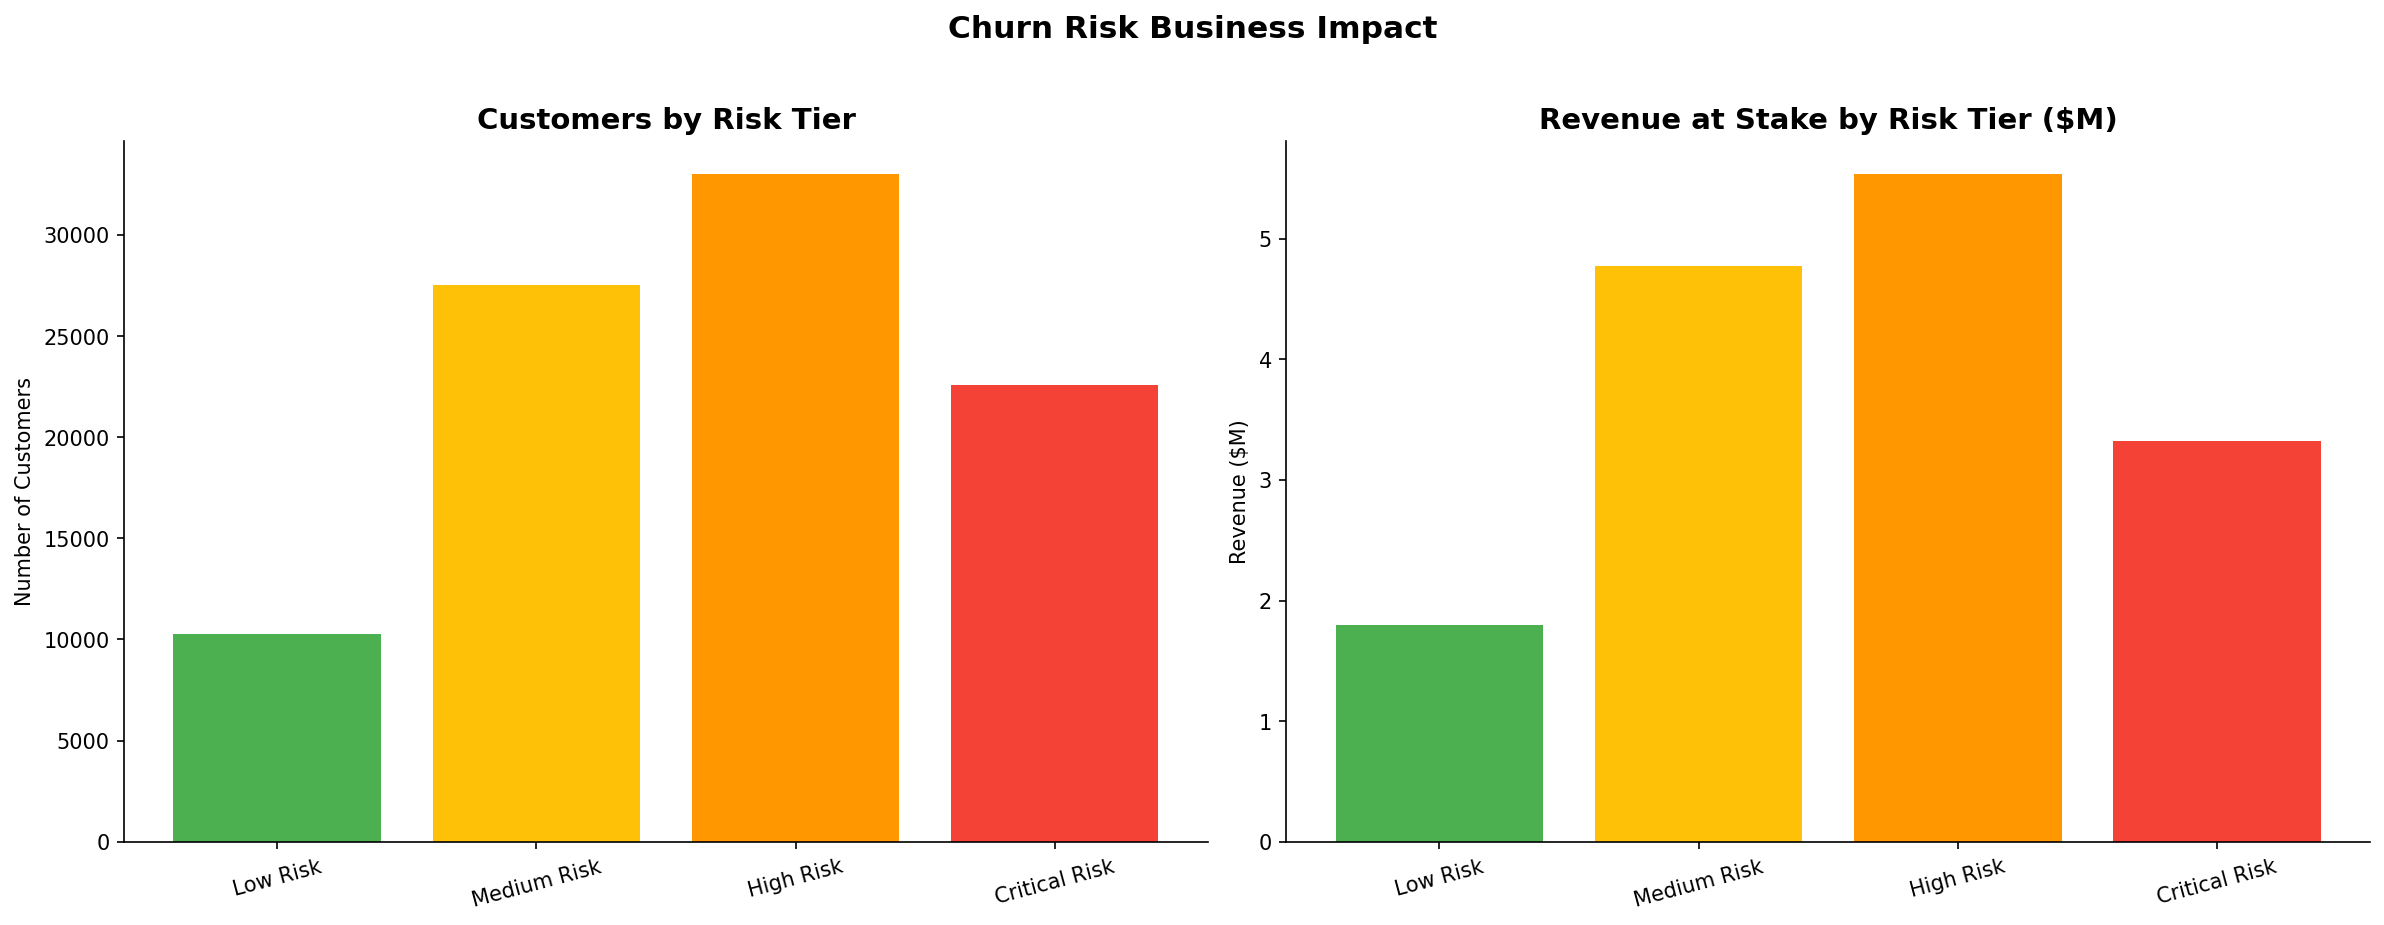

In [7]:
# ── Score ALL customers ───────────────────────────────────────────────────────
X_all    = df[FEATURES]
df["churn_probability"] = xgb_model.predict_proba(X_all)[:, 1]

# Risk tiers
df["risk_tier"] = pd.cut(
    df["churn_probability"],
    bins  = [0, 0.3, 0.5, 0.7, 1.0],
    labels= ["Low Risk", "Medium Risk",
             "High Risk", "Critical Risk"]
)

risk_summary = (
    df.groupby("risk_tier", observed=True)
    .agg(
        num_customers  = ("customer_unique_id", "count"),
        total_revenue  = ("total_spend",        "sum"),
        avg_spend      = ("total_spend",        "mean"),
        avg_churn_prob = ("churn_probability",  "mean"),
    )
    .round(2)
    .reset_index()
)

print("Churn Risk Tier Summary:")
print(risk_summary.to_string(index=False))

# High + critical risk dollar impact
high_risk = df[df["risk_tier"].isin(["High Risk","Critical Risk"])]
print(f"\nHigh + Critical Risk customers : {len(high_risk):,}")
print(f"   Revenue at stake              : ${high_risk['total_spend'].sum():,.0f}")
print(f"   Avg churn probability         : {high_risk['churn_probability'].mean()*100:.1f}%")

# ── Save scored customers to database ────────────────────────────────────────
output_cols = [
    "customer_unique_id", "total_orders", "total_spend",
    "avg_review_score", "recency_days", "churned",
    "churn_probability", "risk_tier", "customer_state"
]
churn_output = df[output_cols].copy()
churn_output["risk_tier"] = churn_output["risk_tier"].astype(str)
churn_output.to_sql("churn_scores", con=engine,
                    if_exists="replace", index=False)

print(f"\nChurn scores saved → table: churn_scores")

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].bar(risk_summary["risk_tier"],
            risk_summary["num_customers"],
            color=["#4CAF50","#FFC107","#FF9800","#F44336"])
axes[0].set_title("Customers by Risk Tier")
axes[0].set_ylabel("Number of Customers")
axes[0].tick_params(axis="x", rotation=15)

axes[1].bar(risk_summary["risk_tier"],
            risk_summary["total_revenue"] / 1e6,
            color=["#4CAF50","#FFC107","#FF9800","#F44336"])
axes[1].set_title("Revenue at Stake by Risk Tier ($M)")
axes[1].set_ylabel("Revenue ($M)")
axes[1].tick_params(axis="x", rotation=15)

plt.suptitle("Churn Risk Business Impact",
             fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(r"D:\customer_intelligence_platform\outputs\13_churn_risk_tiers.png",
            bbox_inches="tight")
plt.show()